# Spatial Accessibility with Pysal Access

**Authors:** Alexander Michels

In this notebook, we use the Pysall `access` package to calculate spatial accessibility to hospital beds using multiple methods.

In [1]:
import access
import contextily as cx
import geopandas as gpd
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm
import sys

In [2]:
pop_id = "FIPS"
figsize=(16, 14)

In [3]:
pop = gpd.read_file("../data/svi/SVI2018_US_tract.shp")
pop = pop[pop["STCNTY"] == "17031"]
pop[pop_id] = pop[pop_id].astype(str)
pop = pop.to_crs("EPSG:4326")
print(len(pop))
pop.head()

1318


,ST,STATE,ST_ABBR,STCNTY,COUNTY,FIPS,LOCATION,AREA_SQMI,E_TOTPOP,M_TOTPOP,...,F_THEME4,F_TOTAL,E_UNINSUR,M_UNINSUR,EP_UNINSUR,MP_UNINSUR,E_DAYPOP,Shape_STAr,Shape_STLe,geometry
184,17,ILLINOIS,IL,17031,Cook,17031381700,"Census Tract 3817, Cook County, Illinois",0.075986,0,11,...,-999,-999,0,11,-999.0,-999.0,551,0.000021,0.020359,"POLYGON ((-87.62892 41.80919, -87.62608 41.809..."
185,17,ILLINOIS,IL,17031,Cook,17031980000,"Census Tract 9800, Cook County, Illinois",7.679554,0,11,...,-999,-999,0,11,-999.0,-999.0,38202,0.002171,0.222431,"POLYGON ((-87.94025 42.00717, -87.93895 42.006..."
186,17,ILLINOIS,IL,17031,Cook,17031980100,"Census Tract 9801, Cook County, Illinois",1.151272,0,11,...,-999,-999,0,11,-999.0,-999.0,6449,0.000323,0.076961,"POLYGON ((-87.7623 41.79274, -87.75251 41.7928..."
12180,17,ILLINOIS,IL,17031,Cook,17031020100,"Census Tract 201, Cook County, Illinois",0.158747,3836,361,...,0,0,569,245,14.8,6.3,3714,0.000044,0.027301,"POLYGON ((-87.6902 42.01682, -87.6902 42.01744..."
12181,17,ILLINOIS,IL,17031,Cook,17031020200,"Census Tract 202, Cook County, Illinois",0.479524,6739,510,...,0,1,628,396,9.3,6.0,3249,0.000135,0.051852,"POLYGON ((-87.70875 42.0155, -87.70866 42.0191..."


In [4]:
# load the hospitals
hos = gpd.read_file("../data/hospitals/ContinentalHospitals.shp")
hos = hos[(hos["STATE"] == "IL") & (hos["COUNTY"] == "COOK")]
hos = hos[hos["BEDS"] >= 0]
hos = hos.to_crs("EPSG:4326")
print(len(hos), sum(hos["BEDS"]))
hos.head()

66 18259


,OBJECTID,ID,NAME,ADDRESS,CITY,STATE,ZIP,ZIP4,TELEPHONE,TYPE,...,WEBSITE,STATE_ID,ALT_NAME,ST_FIPS,OWNER,TTL_STAFF,BEDS,TRAUMA,HELIPAD,geometry
507,1513,0003460644,UHS HARTGROVE HOSPITAL,5730 WEST ROOSEVELT ROAD,CHICAGO,IL,60644,NOT AVAILABLE,(773) 413-1700,PSYCHIATRIC,...,http://www.hartgrovehospital.com,0005454,NOT AVAILABLE,17,PROPRIETARY,-999,128,NOT AVAILABLE,N,POINT (-87.76746 41.86633)
508,1514,0001860612,JESSE BROWN VA MEDICAL CENTER - VA CHICAGO HEA...,820 S DAMEN STREET,CHICAGO,IL,60612,NOT AVAILABLE,(312) 569-8387,MILITARY,...,http://www.chicago.va.gov/,14003F,NOT AVAILABLE,17,GOVERNMENT - FEDERAL,-999,240,NOT AVAILABLE,N,POINT (-87.67704 41.87074)
509,1515,0003160463,PALOS COMMUNITY HOSPITAL,12251 SOUTH 80TH AVENUE,PALOS HEIGHTS,IL,60464,NOT AVAILABLE,(708) 923-4000,GENERAL ACUTE CARE,...,http://www.paloscommunityhospital.org,140062,NOT AVAILABLE,17,NON-PROFIT,-999,377,NOT AVAILABLE,Y,POINT (-87.81344 41.66921)
510,1516,0003660628,ROSELAND COMMUNITY HOSPITAL,45 W 111TH STREET,CHICAGO,IL,60628,NOT AVAILABLE,(773) 995-3000,GENERAL ACUTE CARE,...,http://www.roselandhospital.org,140068,NOT AVAILABLE,17,NON-PROFIT,-999,115,NOT AVAILABLE,N,POINT (-87.62536 41.69223)
511,1517,0002360302,WEST SUBURBAN MEDICAL CENTER,3 ERIE COURT,OAK PARK,IL,60302,NOT AVAILABLE,(708) 383-6200,GENERAL ACUTE CARE,...,http://www.westsuburbanmc.com/Home.aspx,140049,NOT AVAILABLE,17,PROPRIETARY,-999,172,NOT AVAILABLE,N,POINT (-87.77618 41.8914)


In [5]:
hospitals = gpd.sjoin(pop[["FIPS", "geometry"]], hos[["BEDS", "geometry"]], how="inner", predicate="intersects")
hospitals = hospitals.groupby("FIPS").agg({"BEDS": 'sum', "geometry": 'last'})
print(len(hospitals), sum(hospitals["BEDS"]))
hospitals.head()

59 18259


,BEDS,geometry
FIPS,,
17031031000,189,"POLYGON ((-87.67441 41.9761, -87.66961 41.9761..."
17031031300,115,"POLYGON ((-87.65499 41.9764, -87.65428 41.9764..."
17031031400,184,"POLYGON ((-87.65012 41.96916, -87.64964 41.969..."
17031032100,134,"POLYGON ((-87.65634 41.96176, -87.65475 41.961..."
17031040300,279,"POLYGON ((-87.70582 41.98309, -87.70401 41.983..."


In [6]:
# get car travel times
car = pd.read_csv("../data/travel_times/17031-output-TRACT-CAR.csv")
car["origin"] = car["origin"].astype(str)
car["destination"] = car["destination"].astype(str)
car.head()

,origin,destination,minutes
0,17031010100,17007010100,101.35
1,17031010100,17007010200,96.10
2,17031010100,17007010300,96.43
3,17031010100,17007010400,96.17
4,17031010100,17007010500,107.13


In [7]:
# calculate the gravity-based access
A = access.Access(
    demand_df=pop,
    demand_index=pop_id,
    demand_value="E_TOTPOP",
    supply_df=hospitals,
    supply_index=True,
    supply_value="BEDS",
    cost_df=car,
    cost_origin="origin",
    cost_dest="destination",
    cost_name="minutes",
    neighbor_cost_df=car,
    neighbor_cost_origin="origin",
    neighbor_cost_dest="destination",
    neighbor_cost_name="minutes"
)

In [8]:
gravity = access.weights.gravity(scale=60, alpha=-2, min_dist=1)
e2sfca_weights_30 = access.weights.step_fn({10 : 1, 20 : 0.68, 30 : 0.22})
e2sfca_weights_60 = access.weights.step_fn({20 : 1, 40 : 0.68, 60 : 0.22})
gaussian10 = access.weights.gaussian(10)
gaussian20 = access.weights.gaussian(20)

In [9]:
A.weighted_catchment(name="gravity", weight_fn=gravity)

,gravity_BEDS
FIPS,
17031010100,65335.763181
17031010201,84737.705650
17031010202,64835.519563
17031010300,61203.919275
17031010400,68054.999255
...,...
17031843700,124207.182651
17031843800,93708.024179
17031843900,114998.414425


In [10]:
A.two_stage_fca(name="2sfca_30", max_cost=30)
A.two_stage_fca(name="2sfca_60", max_cost=60)

/home/dijkstra/Documents/GitHubRepos/AgentAccess/venv/lib/python3.12/site-packages/access/fca.py:287: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  temp[supply_name].fillna(0, inplace=True)
/home/dijkstra/Documents/GitHubRepos/AgentAccess/venv/lib/python3.12/site-packages/access/fca.py:287: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on

,2sfca_60_BEDS
FIPS,
17031010100,0.002790
17031010201,0.003022
17031010202,0.002956
17031010300,0.002931
17031010400,0.003050
...,...
17031843700,0.003858
17031843800,0.003801
17031843900,0.003801


In [11]:
A.enhanced_two_stage_fca(name="e2sfca_30", weight_fn=e2sfca_weights_30, max_cost=30)
A.enhanced_two_stage_fca(name="e2sfca_60", weight_fn=e2sfca_weights_60, max_cost=60)

/home/dijkstra/Documents/GitHubRepos/AgentAccess/venv/lib/python3.12/site-packages/access/fca.py:287: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  temp[supply_name].fillna(0, inplace=True)
/home/dijkstra/Documents/GitHubRepos/AgentAccess/venv/lib/python3.12/site-packages/access/fca.py:287: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on

,e2sfca_60_BEDS
FIPS,
17031010100,0.002484
17031010201,0.002714
17031010202,0.002645
17031010300,0.002648
17031010400,0.003023
...,...
17031843700,0.004963
17031843800,0.004360
17031843900,0.004146


In [12]:
A.enhanced_two_stage_fca(name="g2sfca10", weight_fn=gaussian10)
A.enhanced_two_stage_fca(name="g2sfca20", weight_fn=gaussian20)

/home/dijkstra/Documents/GitHubRepos/AgentAccess/venv/lib/python3.12/site-packages/access/fca.py:287: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  temp[supply_name].fillna(0, inplace=True)
/home/dijkstra/Documents/GitHubRepos/AgentAccess/venv/lib/python3.12/site-packages/access/fca.py:287: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on

,g2sfca20_BEDS
FIPS,
17031010100,0.002699
17031010201,0.002867
17031010202,0.002820
17031010300,0.002814
17031010400,0.003120
...,...
17031843700,0.005420
17031843800,0.004511
17031843900,0.004258


In [13]:
A.three_stage_fca(name="3sfca")

/home/dijkstra/Documents/GitHubRepos/AgentAccess/venv/lib/python3.12/site-packages/access/fca.py:408: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  temp[supply_name].fillna(0, inplace=True)


,3sfca_BEDS
FIPS,
17031010100,0.005337
17031010201,0.005148
17031010202,0.005539
17031010300,0.005940
17031010400,0.004095
...,...
17031843700,0.004093
17031843800,0.002721
17031843900,0.004008


In [14]:
A.raam(name="raam30", tau=30)
A.raam(name="raam60", tau=60)

,raam60_BEDS
FIPS,
17031010100,1.151754
17031010201,1.115558
17031010202,1.173011
17031010300,1.187285
17031010400,1.126623
...,...
17031843700,1.139529
17031843800,1.194155
17031843900,1.184715


In [15]:
print(len(A.access_df))
A.access_df.head()

1318


,E_TOTPOP,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS
FIPS,,,,,,,,,,,
17031010100,4522,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754
17031010201,7039,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558
17031010202,2852,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011
17031010300,6650,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285
17031010400,5153,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623


In [16]:
access_result = A.access_df.merge(pop[["FIPS", "geometry"]], left_index=True, right_on="FIPS").set_index("FIPS")
access_result = gpd.GeoDataFrame(access_result)
access_result = access_result.drop(columns=["E_TOTPOP"])
print(len(access_result))
print(type(access_result))
access_result.head()

1318
<class 'geopandas.geodataframe.GeoDataFrame'>


,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry
FIPS,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.6772 42.02294, -87.67007 42.0229..."
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68465 42.01949, -87.68045 42.019..."
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67685 42.01941, -87.67339 42.019..."
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.67133 42.01937, -87.6695 42.0193..."
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66345 42.01283, -87.66133 42.012..."


In [17]:
supply_field = "BEDS"
result_cols = [
    "gravity",
    "2sfca_30", "2sfca_60", "e2sfca_30", 
    "e2sfca_60", "g2sfca10", "g2sfca20",
    "3sfca", "raam30", "raam60"
]
result_cols = [x + f"_{supply_field}" for x in result_cols]
result_title_mapper = [
    "Gravity",
    "2SFCA 30 mins",
    "2SFCA 60 mins",
    "E2SFCA 30 mins",
    "E2SFCA 60 mins",
    "Gaussian 2SFCA 10",
    "Gaussian 2SFCA 20",
    "3SFCA",
    "RAAM 30",
    "RAAM 60"
]

In [18]:
result = A.access_df.reset_index()
result[pop_id] = result[pop_id].astype(str)
# replace zeroes with nan to help distinguish between low and no access
for result_col in result_cols:
    result[result_col] = result[result_col].replace(0, np.nan)
    if "fca" in result_col:
        result[result_col] = result[result_col] * 1000
result.head()

,FIPS,E_TOTPOP,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS
0,17031010100,4522,65335.763181,3.517341,2.789702,4.004504,2.484304,3.534478,2.699279,5.337051,1.353203,1.151754
1,17031010201,7039,84737.705650,3.517341,3.021908,4.238741,2.713838,3.749202,2.866898,5.148290,1.278645,1.115558
2,17031010202,2852,64835.519563,3.517341,2.956273,4.370712,2.645193,3.102013,2.820337,5.538859,1.375311,1.173011
3,17031010300,6650,61203.919275,3.517341,2.931341,4.461809,2.647708,2.879686,2.813522,5.939814,1.428868,1.187285
4,17031010400,5153,68054.999255,3.313634,3.049738,2.968855,3.023287,2.651226,3.120398,4.095070,1.375371,1.126623


,FIPS,geometry,E_TOTPOP,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS
0,17031381700,"POLYGON ((-87.62892 41.80919, -87.62608 41.809...",0,99914.136676,4.886406,3.800530,4.709692,4.417457,3.431033,4.737343,3.667343,NaN,NaN
1,17031980000,"POLYGON ((-87.94025 42.00717, -87.93895 42.006...",0,46504.306308,1.206447,3.613332,0.744261,3.538265,0.573157,2.563694,1.265997,NaN,NaN
2,17031980100,"POLYGON ((-87.7623 41.79274, -87.75251 41.7928...",0,65755.876382,4.390195,3.800530,2.796026,3.975360,1.389897,3.692069,2.473322,NaN,NaN
3,17031020100,"POLYGON ((-87.6902 42.01682, -87.6902 42.01744...",3836,90724.790721,3.517341,3.122618,4.238741,2.825198,3.881464,2.924917,4.924230,1.265311,1.110285
4,17031020200,"POLYGON ((-87.70875 42.0155, -87.70866 42.0191...",6739,71235.808359,3.117672,3.227896,4.052871,3.269375,3.443119,3.030194,4.206705,1.340311,1.149850


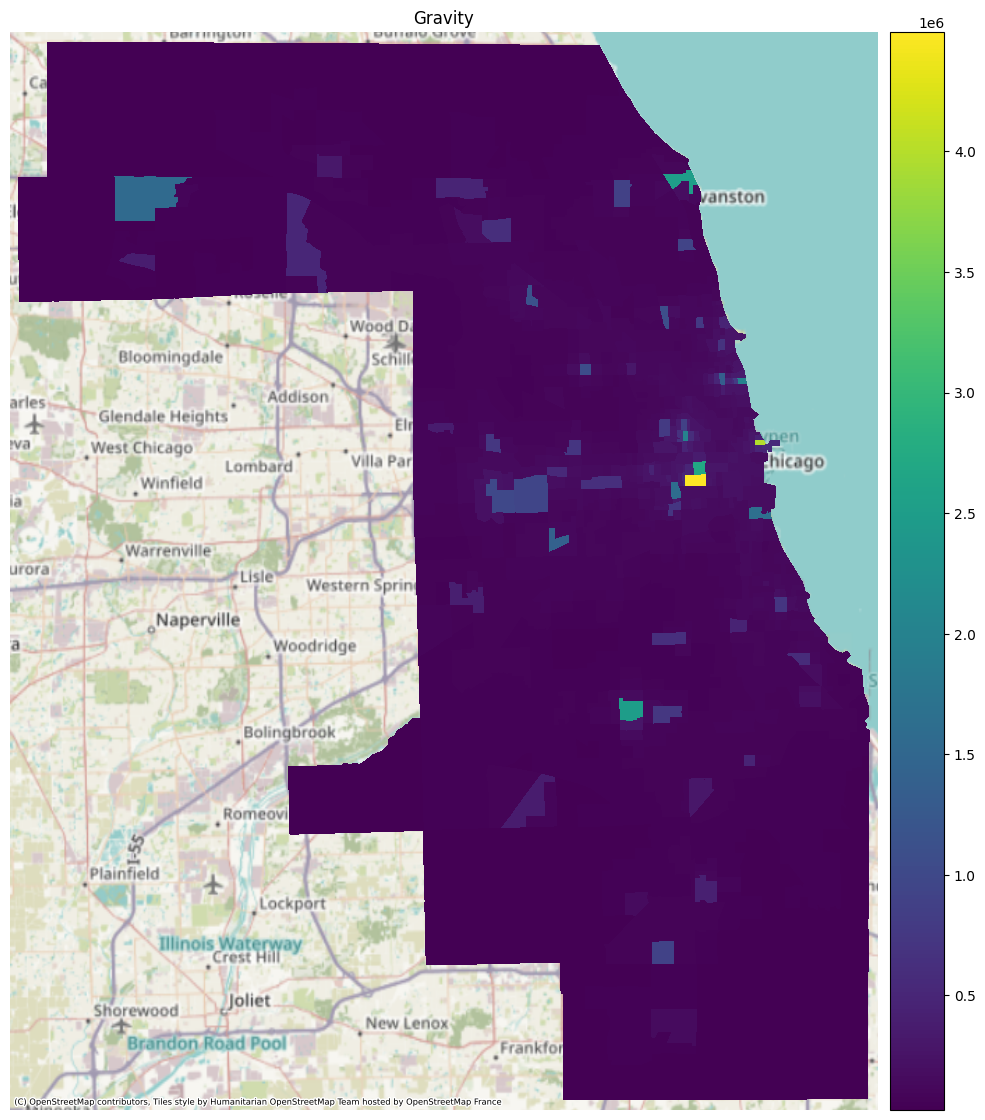

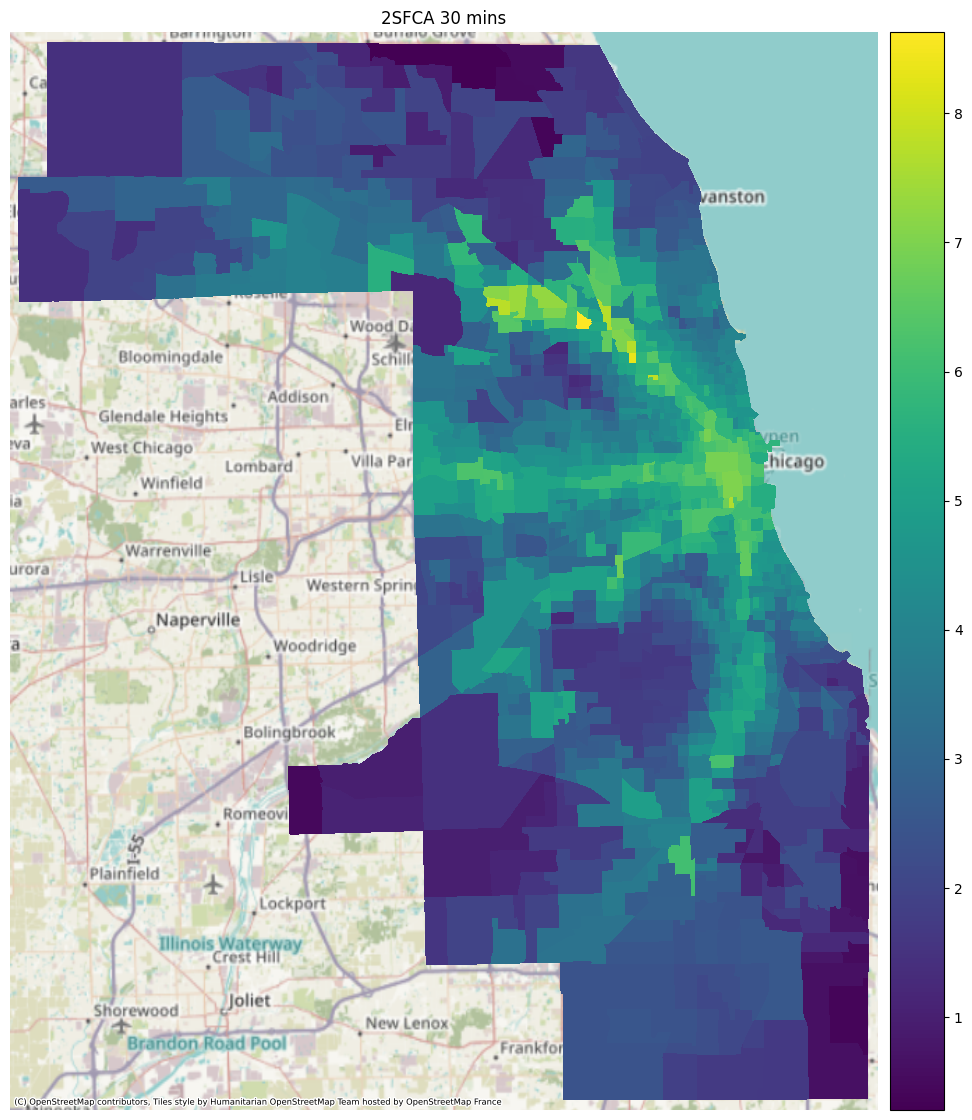

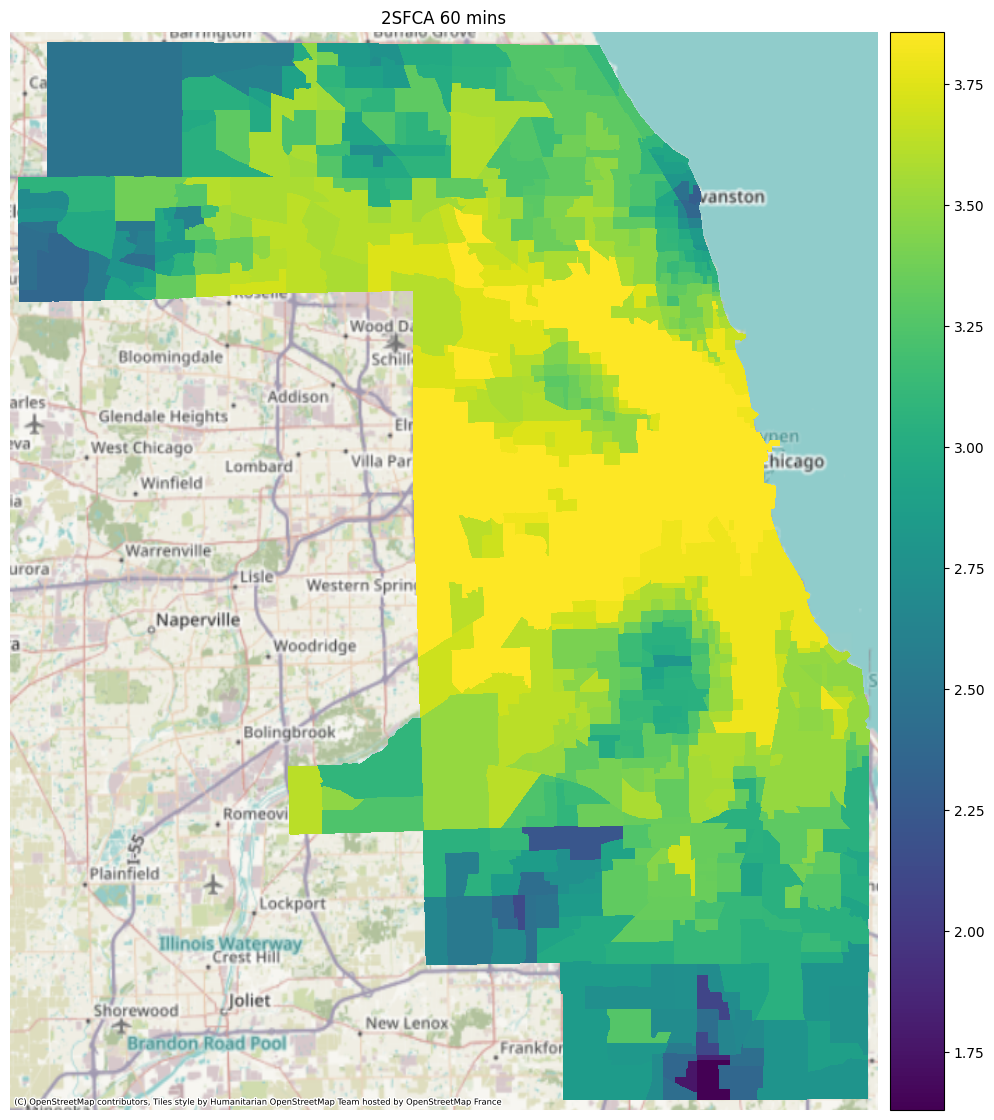

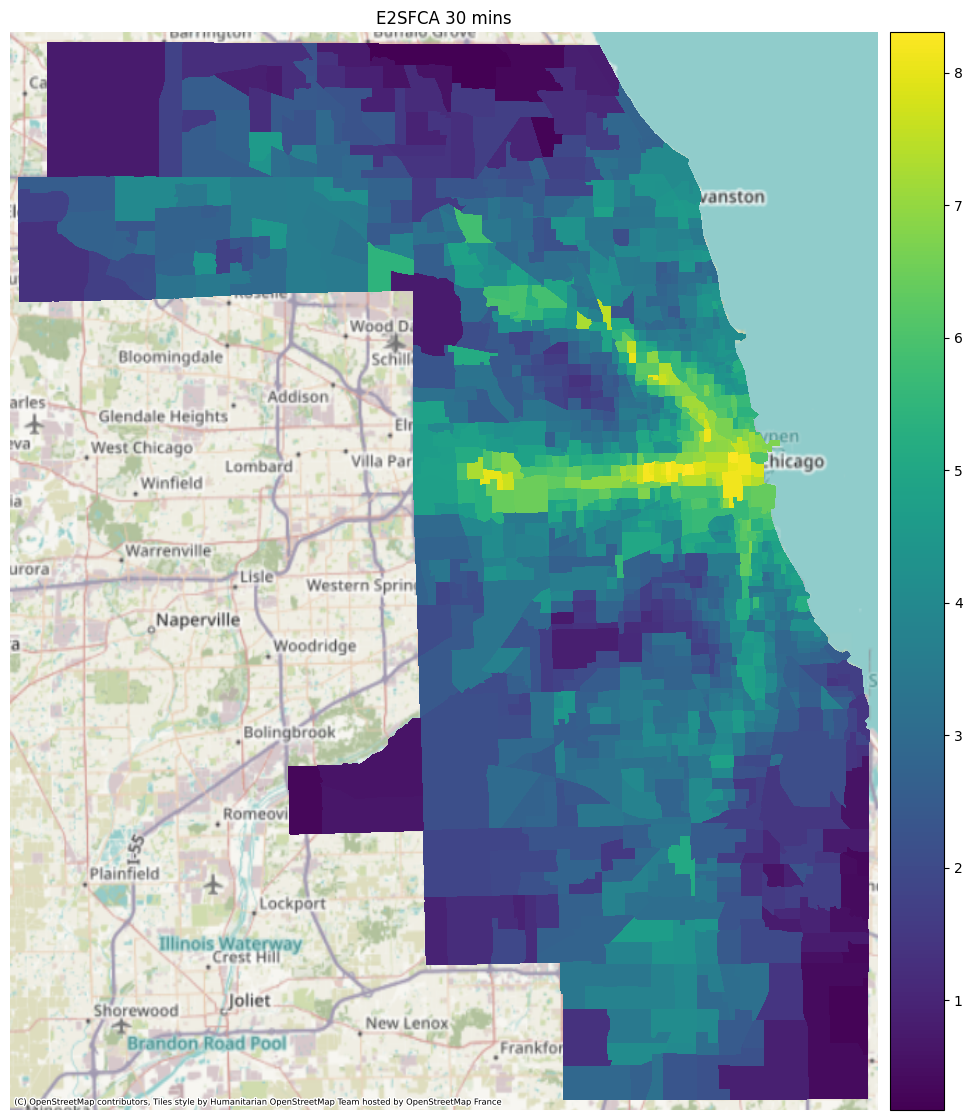

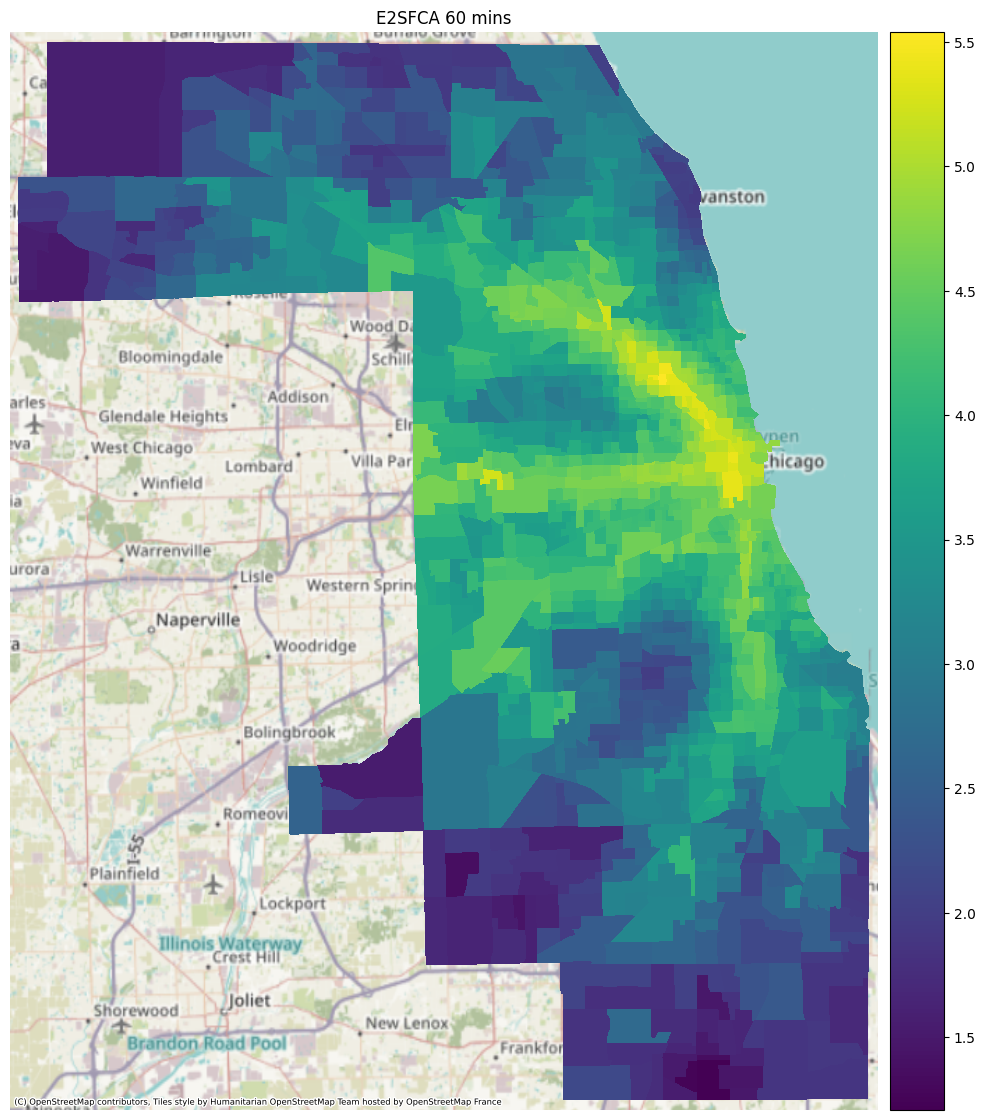

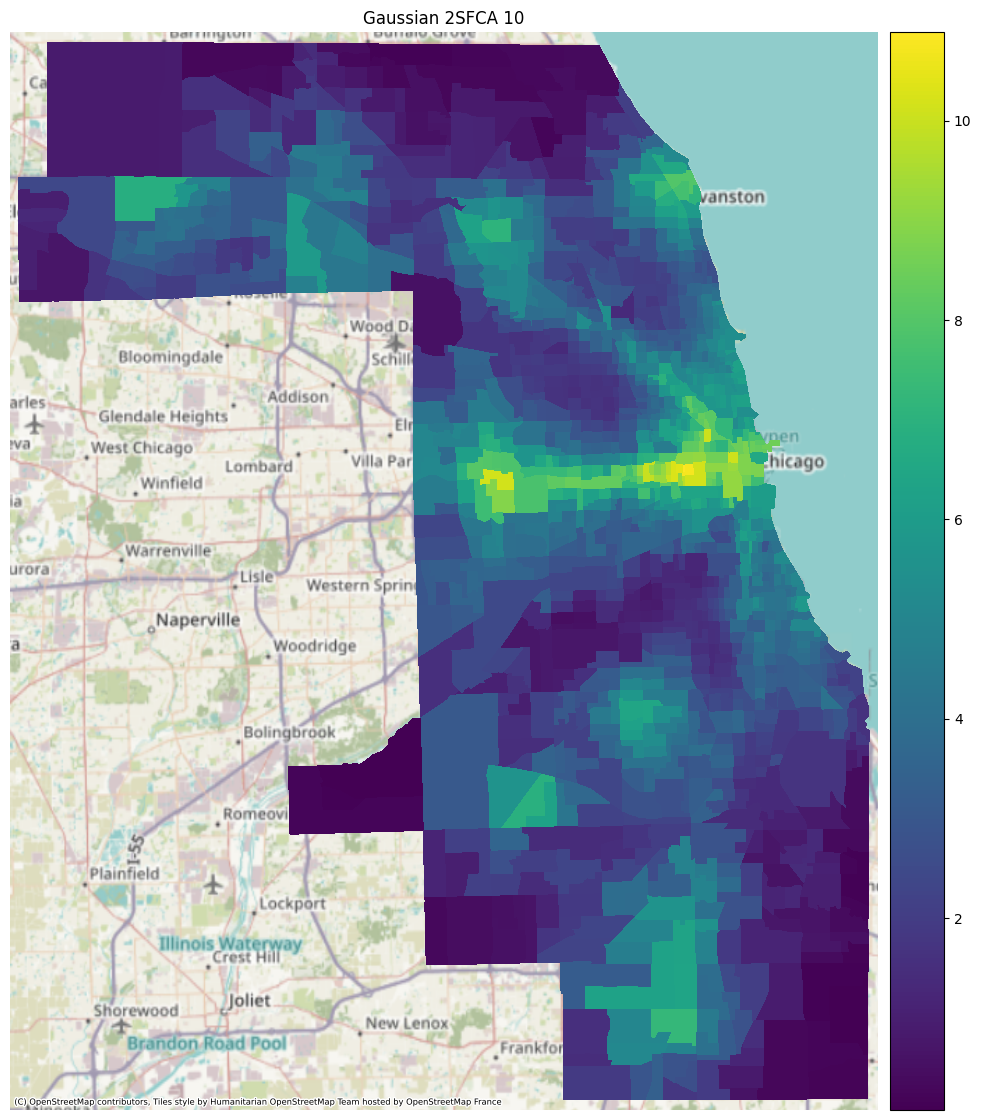

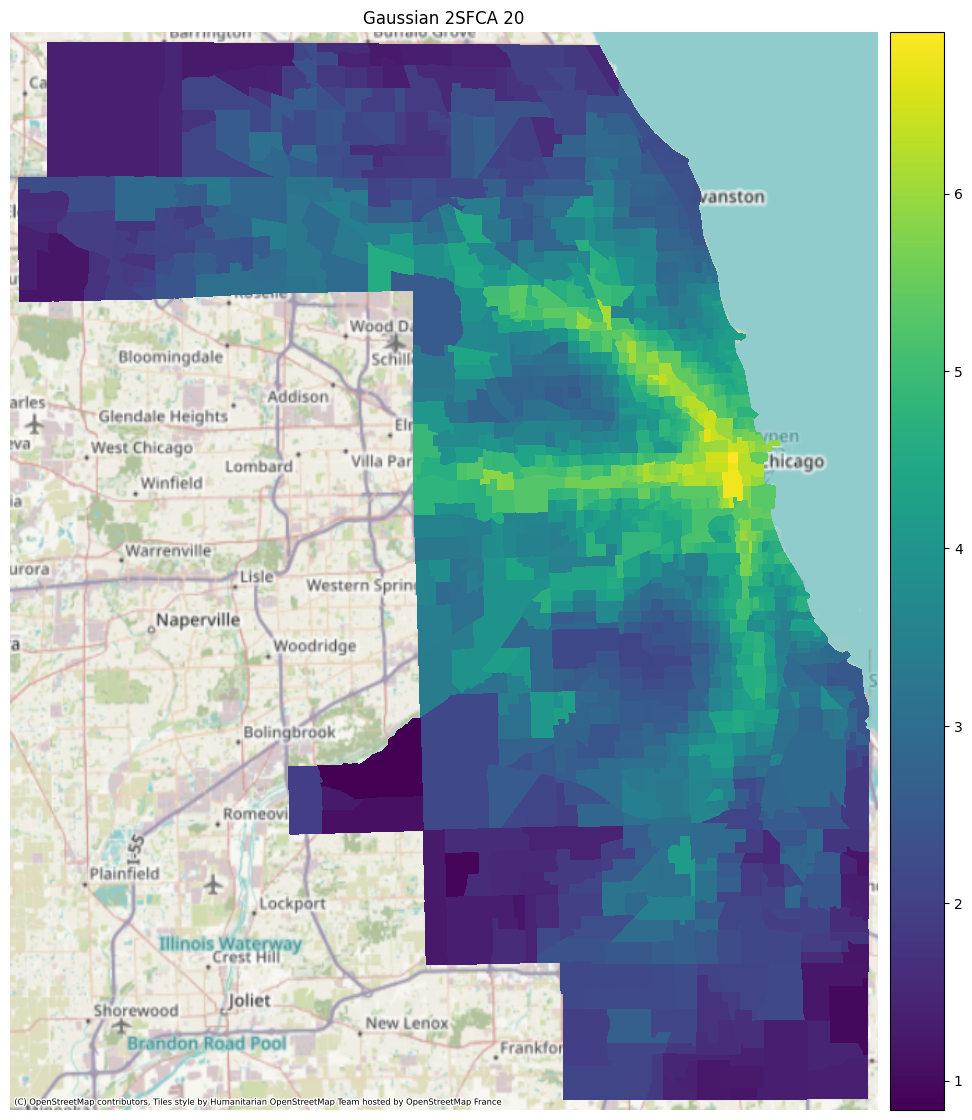

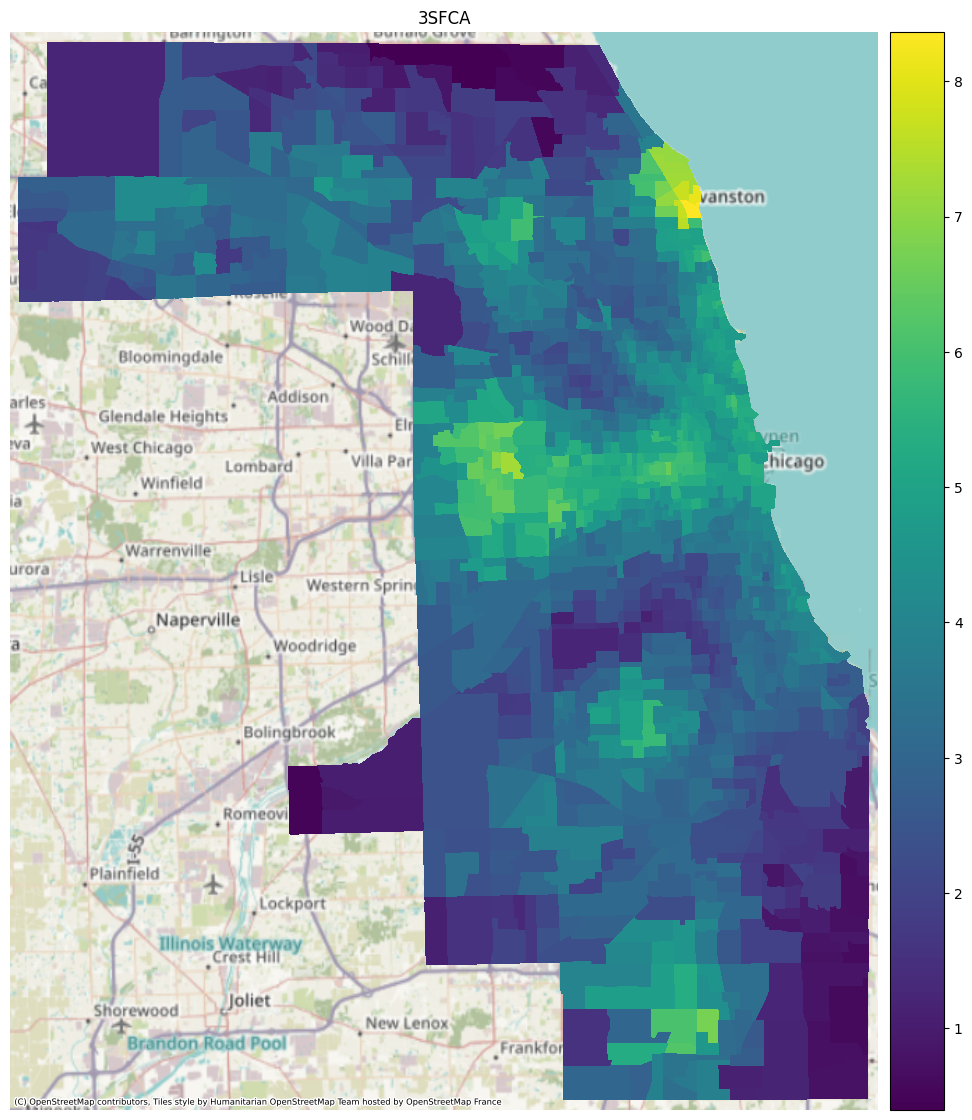

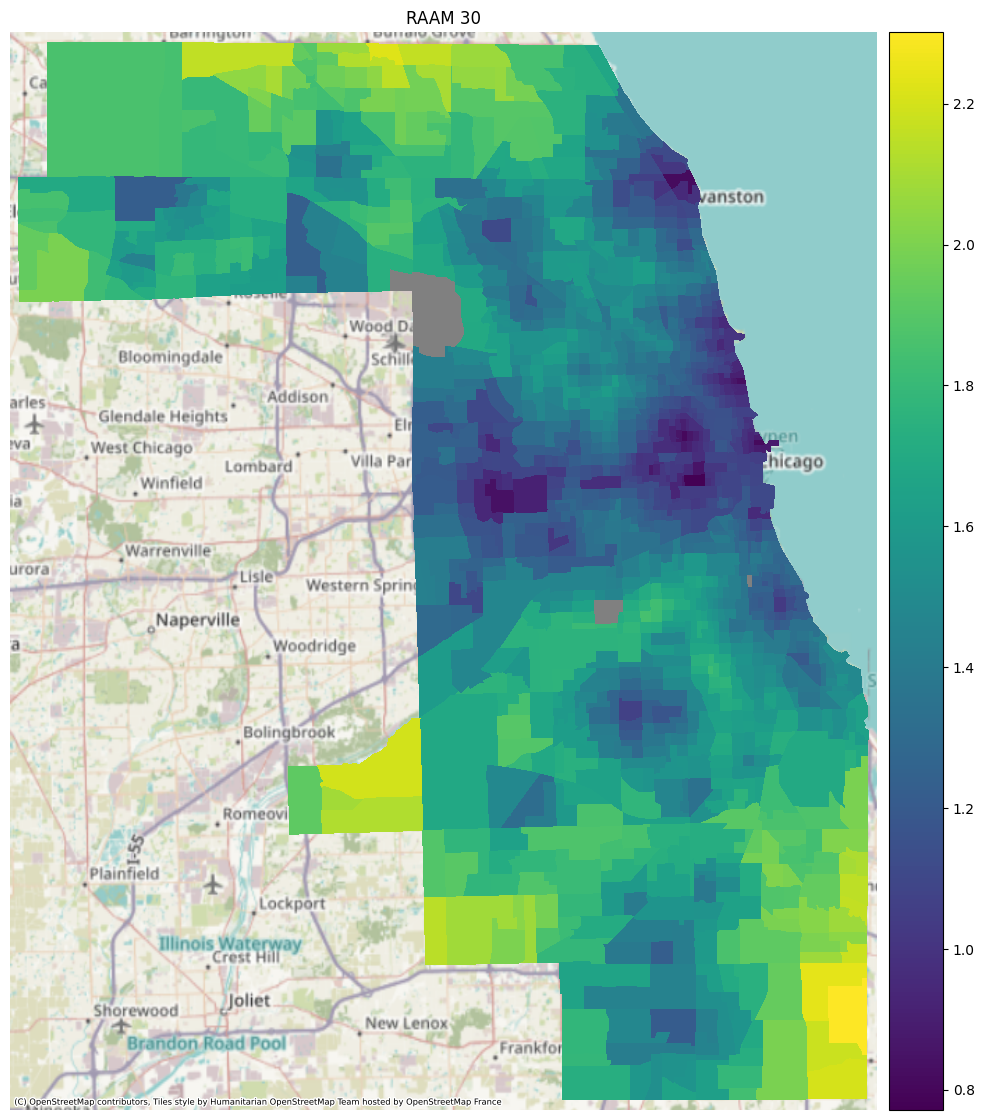

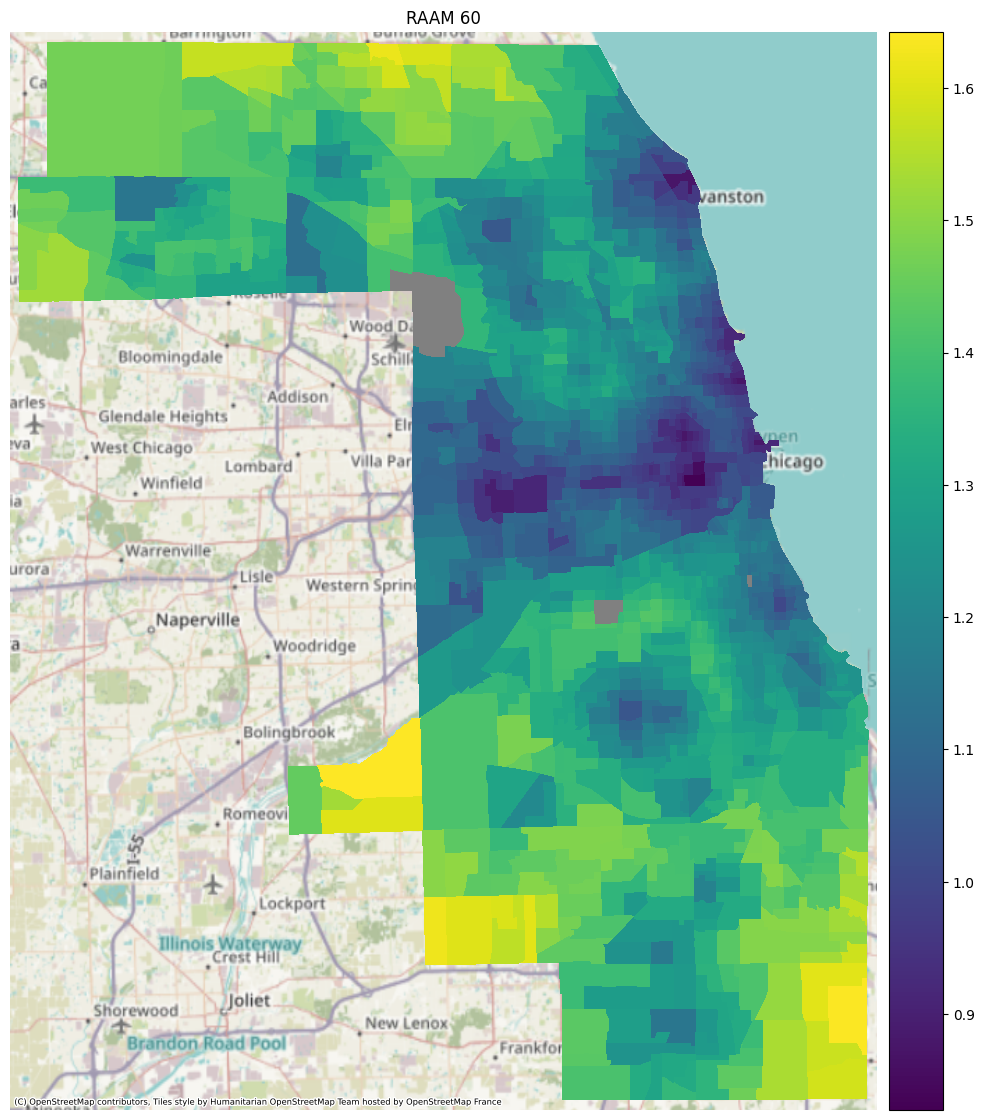

In [19]:
geom_result = gpd.GeoDataFrame(pop[[pop_id, "geometry"]].merge(result, on=pop_id))
geom_result = geom_result.set_crs(pop.crs)
for i, result_col in enumerate(result_cols):
    fig, ax = plt.subplots(figsize=figsize)
    ax = geom_result.plot(ax=ax, column=result_col, figsize=figsize, legend=True, antialiased=False,
                                missing_kwds= dict(color = "grey",), legend_kwds={'pad' : 0.01})
    ax.set_title(result_title_mapper[i])
    ax.margins(0.01)
    fig.subplots_adjust(hspace=0.0, wspace=0.0)
    ax.set_axis_off()
    cx.add_basemap(ax, attribution_size=6, crs=geom_result.crs.to_string())
geom_result.head()

In [20]:
corr = access_result.corr(method='kendall', numeric_only=True)
corr.style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1)

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS
gravity_BEDS,1.000000,0.508037,0.549093,0.605605,0.591693,0.622709,0.654312,0.525714,-0.735198,-0.720097
2sfca_30_BEDS,0.508037,1.000000,0.617829,0.660640,0.702800,0.428490,0.763236,0.354754,-0.403097,-0.409948
2sfca_60_BEDS,0.549093,0.617829,1.000000,0.538545,0.791337,0.414585,0.748613,0.341379,-0.450638,-0.468534
e2sfca_30_BEDS,0.605605,0.660640,0.538545,1.000000,0.607776,0.708454,0.694587,0.646136,-0.594559,-0.589544
e2sfca_60_BEDS,0.591693,0.702800,0.791337,0.607776,1.000000,0.439592,0.869909,0.333908,-0.449454,-0.464655
g2sfca10_BEDS,0.622709,0.428490,0.414585,0.708454,0.439592,1.000000,0.517882,0.709587,-0.689235,-0.665462
g2sfca20_BEDS,0.654312,0.763236,0.748613,0.694587,0.869909,0.517882,1.000000,0.404641,-0.514542,-0.527022
3sfca_BEDS,0.525714,0.354754,0.341379,0.646136,0.333908,0.709587,0.404641,1.000000,-0.666412,-0.659424
raam30_BEDS,-0.735198,-0.403097,-0.450638,-0.594559,-0.449454,-0.689235,-0.514542,-0.666412,1.000000,0.898447
raam60_BEDS,-0.720097,-0.409948,-0.468534,-0.589544,-0.464655,-0.665462,-0.527022,-0.659424,0.898447,1.000000


In [21]:
access_result.to_file("../data/accessibility/CookHospitals.gpkg", driver="GPKG")